In [8]:
import pandas as pd

In [9]:
def freight_loading():
    csv_path="train-test-exp.csv"
    return pd.read_csv(csv_path)

In [10]:
freight=freight_loading()
freight.head()

,load_id,pickup,delivery,pickup_lat,pickup_lon,delivery_lat,delivery_lon,distance,equipment,weight,date,market_index,quote_signal,posted_rate
0,TR-000001,Richmond,Baltimore,38.09122,-76.78906,38.16908,-72.74564,274.3,Dry Van,30658.0,2025-01-01,0.95684,2.39595,645.41
1,TR-000002,Richmond,Philadelphia,38.09122,-76.78906,39.22317,-72.96710,280.5,Reefer,17555.0,2025-01-01,0.97623,2.43355,679.97
2,TR-000003,Philadelphia,Green Bay,39.22317,-72.96710,44.30296,-87.52871,967.8,Dry Van,31721.0,2025-01-01,1.00971,1.84491,1802.54
3,TR-000004,Hartford,Atlanta,39.55328,-72.18051,34.84933,-86.28940,965.4,Dry Van,32333.0,2025-01-01,0.94518,1.87712,1827.28
4,TR-000005,Dallas,Nashville,31.83025,-94.38343,35.29479,-88.08915,541.9,Reefer,35183.0,2025-01-01,0.98480,2.56300,1380.28


## Understanding missing data and data types

In [11]:
freight.info()

<class 'pandas.DataFrame'>
RangeIndex: 48000 entries, 0 to 47999
Data columns (total 14 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   load_id       48000 non-null  str    
 1   pickup        48000 non-null  str    
 2   delivery      48000 non-null  str    
 3   pickup_lat    48000 non-null  float64
 4   pickup_lon    48000 non-null  float64
 5   delivery_lat  48000 non-null  float64
 6   delivery_lon  48000 non-null  float64
 7   distance      48000 non-null  float64
 8   equipment     48000 non-null  str    
 9   weight        47700 non-null  float64
 10  date          48000 non-null  str    
 11  market_index  47626 non-null  float64
 12  quote_signal  48000 non-null  float64
 13  posted_rate   48000 non-null  float64
dtypes: float64(9), str(5)
memory usage: 5.1 MB


## Exploring data deeply to understand its distribution

In [12]:
%matplotlib inline

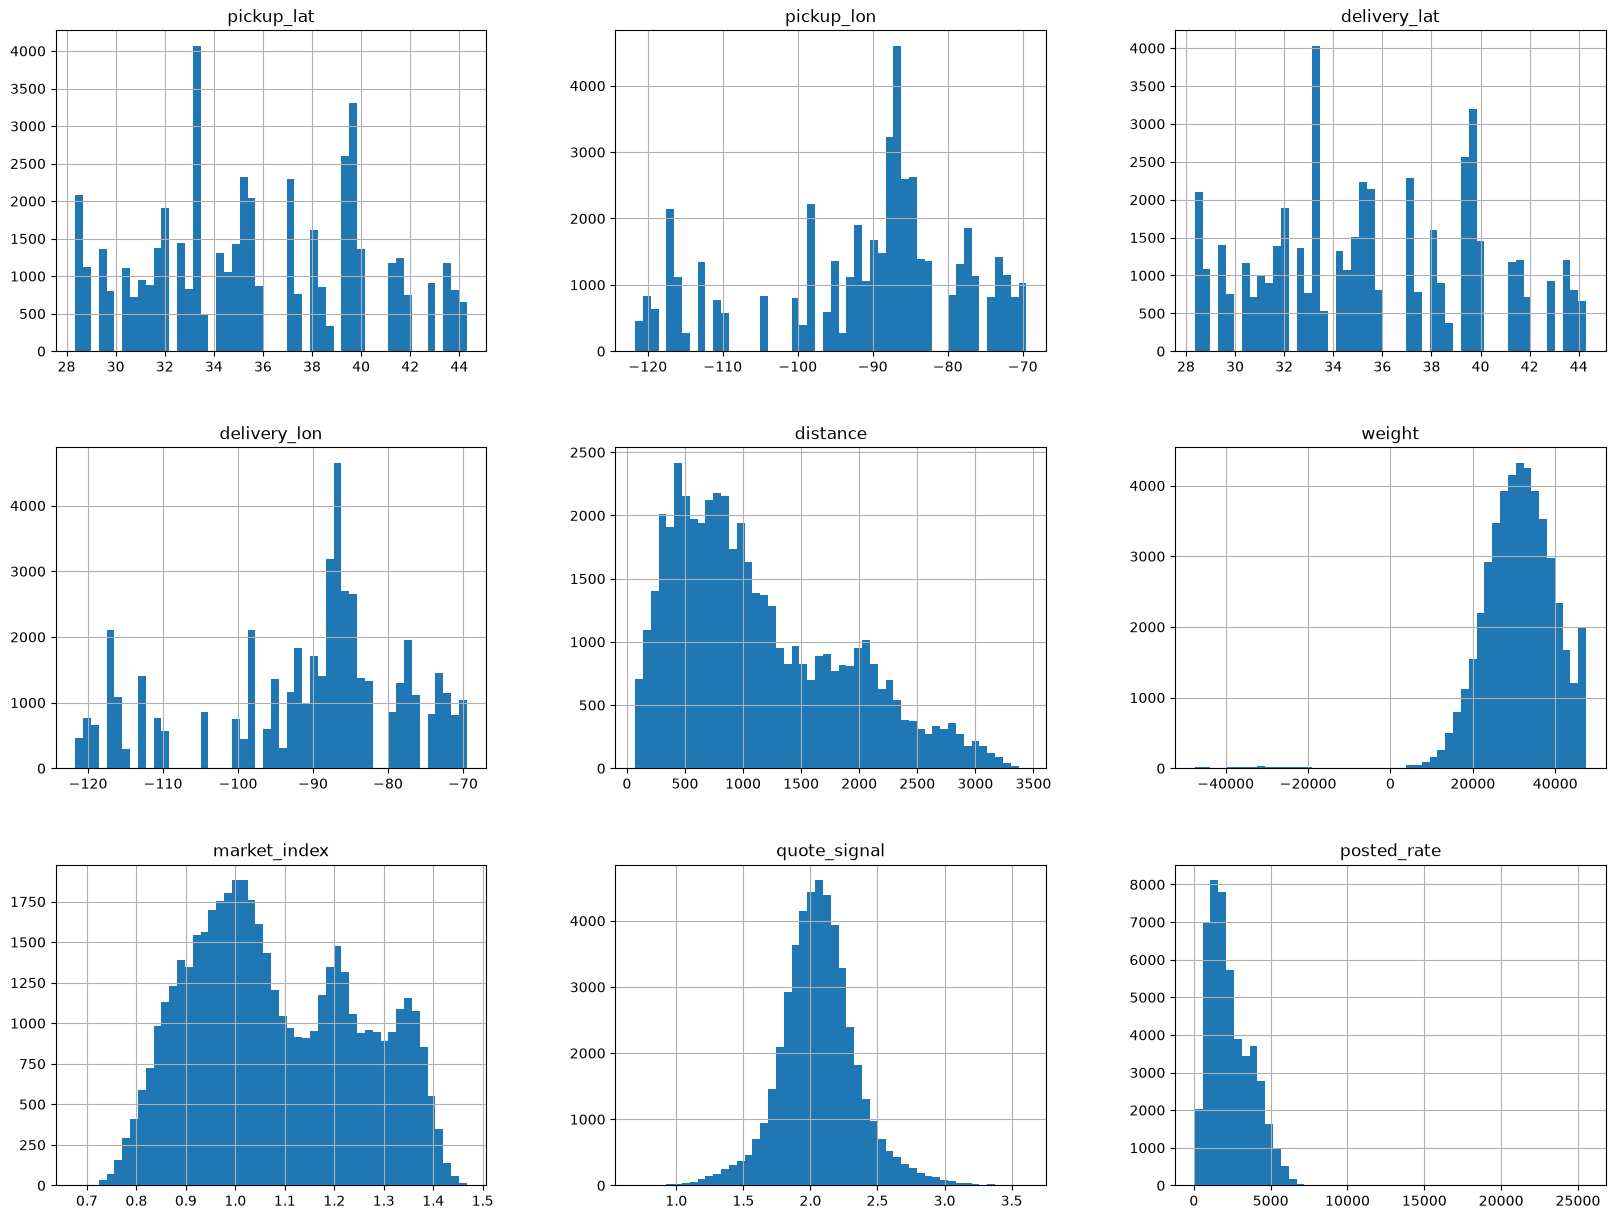

In [13]:
import matplotlib.pyplot as plt
freight.hist(bins=50,figsize=(20,15))
plt.show()

## market index is higly correlated with date

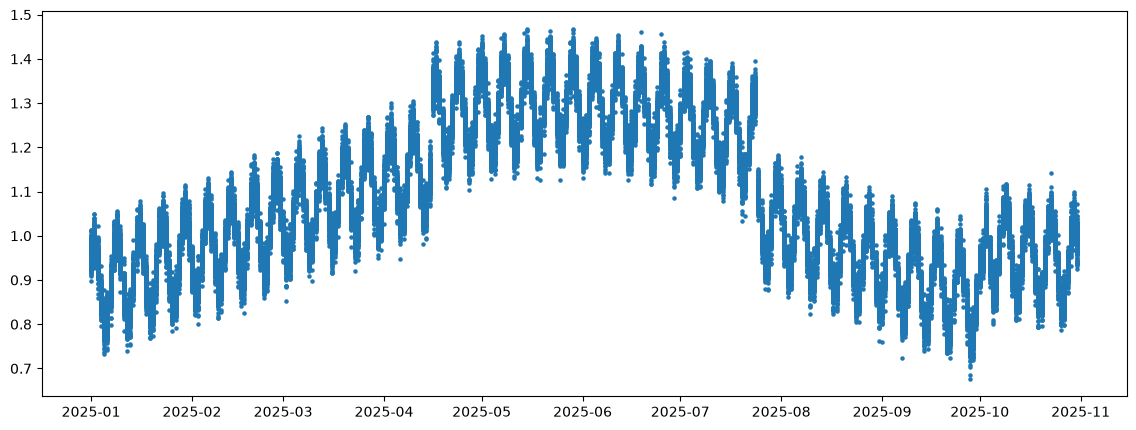

In [14]:
freight["date"] = pd.to_datetime(freight["date"])

plt.figure(figsize=(14,5))
plt.scatter(freight["date"], freight["market_index"], s=5)
plt.show()

## Transforming date into machine readable format

In [15]:
freight["date"] = pd.to_datetime(freight["date"], format="%d-%m-%Y")

freight["month"] = freight["date"].dt.month
freight["day"] = freight["date"].dt.day
freight["weekday"] = freight["date"].dt.weekday
freight["week_of_year"] = freight["date"].dt.isocalendar().week
freight["day_of_year"] = freight["date"].dt.dayofyear

In [16]:
freight.head()

,load_id,pickup,delivery,pickup_lat,pickup_lon,delivery_lat,delivery_lon,distance,equipment,weight,date,market_index,quote_signal,posted_rate,month,day,weekday,week_of_year,day_of_year
0,TR-000001,Richmond,Baltimore,38.09122,-76.78906,38.16908,-72.74564,274.3,Dry Van,30658.0,2025-01-01,0.95684,2.39595,645.41,1,1,2,1,1
1,TR-000002,Richmond,Philadelphia,38.09122,-76.78906,39.22317,-72.96710,280.5,Reefer,17555.0,2025-01-01,0.97623,2.43355,679.97,1,1,2,1,1
2,TR-000003,Philadelphia,Green Bay,39.22317,-72.96710,44.30296,-87.52871,967.8,Dry Van,31721.0,2025-01-01,1.00971,1.84491,1802.54,1,1,2,1,1
3,TR-000004,Hartford,Atlanta,39.55328,-72.18051,34.84933,-86.28940,965.4,Dry Van,32333.0,2025-01-01,0.94518,1.87712,1827.28,1,1,2,1,1
4,TR-000005,Dallas,Nashville,31.83025,-94.38343,35.29479,-88.08915,541.9,Reefer,35183.0,2025-01-01,0.98480,2.56300,1380.28,1,1,2,1,1


## Drop original date column and invalid negative "weight" rows

In [17]:
freight.drop(columns=["date"], inplace=True)
freight = freight[freight["weight"] >= 0].reset_index(drop=True)

In [18]:
freight.info()

<class 'pandas.DataFrame'>
RangeIndex: 47408 entries, 0 to 47407
Data columns (total 18 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   load_id       47408 non-null  str    
 1   pickup        47408 non-null  str    
 2   delivery      47408 non-null  str    
 3   pickup_lat    47408 non-null  float64
 4   pickup_lon    47408 non-null  float64
 5   delivery_lat  47408 non-null  float64
 6   delivery_lon  47408 non-null  float64
 7   distance      47408 non-null  float64
 8   equipment     47408 non-null  str    
 9   weight        47408 non-null  float64
 10  market_index  47038 non-null  float64
 11  quote_signal  47408 non-null  float64
 12  posted_rate   47408 non-null  float64
 13  month         47408 non-null  int32  
 14  day           47408 non-null  int32  
 15  weekday       47408 non-null  int32  
 16  week_of_year  47408 non-null  UInt32 
 17  day_of_year   47408 non-null  int32  
dtypes: UInt32(1), float64(9), int32(4), s

In [19]:
corr_matrix = freight.corr(numeric_only=True)

In [20]:
corr_matrix["posted_rate"].sort_values(ascending=False)

posted_rate     1.000000
distance        0.908552
weight          0.041674
market_index    0.033716
week_of_year    0.024431
day_of_year     0.024362
month           0.023671
day             0.010306
weekday        -0.003314
quote_signal   -0.039820
pickup_lat     -0.090810
delivery_lat   -0.091642
pickup_lon     -0.254386
delivery_lon   -0.257343
Name: posted_rate, dtype: float64

In [21]:
import pandas as pd
import numpy as np

freight["distance_cat"] = pd.cut(
    freight["distance"],
    bins=[0, 250, 500, 750, 1000, 1500, np.inf],
    labels=[1, 2, 3, 4, 5, 6]
)

In [22]:
freight["distance_cat"].value_counts().sort_index()

distance_cat
1     2679
2     7487
3     7551
4     7315
5     8889
6    13487
Name: count, dtype: int64

In [23]:
freight.iloc[2679]

load_id          TR-002725
pickup            Syracuse
delivery        Montgomery
pickup_lat        42.80915
pickup_lon       -76.89973
delivery_lat      31.37602
delivery_lon     -86.10743
distance            1085.4
equipment           Reefer
weight             27834.0
market_index       0.85766
quote_signal        2.0794
posted_rate        2265.13
month                    1
day                     18
weekday                  5
week_of_year             3
day_of_year             18
distance_cat             5
Name: 2679, dtype: object

In [24]:
freight.groupby("distance_cat")["posted_rate"].mean()

distance_cat
1     490.166913
2     937.841941
3    1421.890132
4    1906.605605
5    2584.819096
6    4193.171672
Name: posted_rate, dtype: float64

### Exploratory analysis showed that distance had the strongest linear relationship with posted_rate (r = 0.91). 

### Furthermore, the average freight rate increased monotonically across distance bins. 

### Therefore, stratified sampling based on distance categories was used to preserve the distribution of the most influential feature across training and validation sets.

## Doing Train-Test Split using stratified shuffle split 80-20 %

In [25]:
from sklearn.model_selection import StratifiedShuffleSplit

split = StratifiedShuffleSplit(n_splits=1,test_size=0.2,random_state=42)
for train_index,test_index in split.split(freight,freight["distance_cat"]):
                               strat_train_set = freight.iloc[train_index]
                               strat_test_set  = freight.iloc[test_index]

In [26]:
strat_train_set.info()

<class 'pandas.DataFrame'>
Index: 37926 entries, 34953 to 29985
Data columns (total 19 columns):
 #   Column        Non-Null Count  Dtype   
---  ------        --------------  -----   
 0   load_id       37926 non-null  str     
 1   pickup        37926 non-null  str     
 2   delivery      37926 non-null  str     
 3   pickup_lat    37926 non-null  float64 
 4   pickup_lon    37926 non-null  float64 
 5   delivery_lat  37926 non-null  float64 
 6   delivery_lon  37926 non-null  float64 
 7   distance      37926 non-null  float64 
 8   equipment     37926 non-null  str     
 9   weight        37926 non-null  float64 
 10  market_index  37635 non-null  float64 
 11  quote_signal  37926 non-null  float64 
 12  posted_rate   37926 non-null  float64 
 13  month         37926 non-null  int32   
 14  day           37926 non-null  int32   
 15  weekday       37926 non-null  int32   
 16  week_of_year  37926 non-null  UInt32  
 17  day_of_year   37926 non-null  int32   
 18  distance_cat  3792

In [22]:
strat_test_set.info()

<class 'pandas.DataFrame'>
Index: 9482 entries, 29449 to 13266
Data columns (total 19 columns):
 #   Column        Non-Null Count  Dtype   
---  ------        --------------  -----   
 0   load_id       9482 non-null   str     
 1   pickup        9482 non-null   str     
 2   delivery      9482 non-null   str     
 3   pickup_lat    9482 non-null   float64 
 4   pickup_lon    9482 non-null   float64 
 5   delivery_lat  9482 non-null   float64 
 6   delivery_lon  9482 non-null   float64 
 7   distance      9482 non-null   float64 
 8   equipment     9482 non-null   str     
 9   weight        9482 non-null   float64 
 10  market_index  9403 non-null   float64 
 11  quote_signal  9482 non-null   float64 
 12  posted_rate   9482 non-null   float64 
 13  month         9482 non-null   int32   
 14  day           9482 non-null   int32   
 15  weekday       9482 non-null   int32   
 16  week_of_year  9482 non-null   UInt32  
 17  day_of_year   9482 non-null   int32   
 18  distance_cat  9482 

## Lets create an copy of train set for data manipulation and understanding so we dont disturb original train set

In [27]:
freight_copy = strat_train_set.copy()

## Drop Target posted_rate and copy it in freight_labels




In [28]:
freight_copy = strat_train_set.drop("posted_rate", axis=1)
y_train = strat_train_set["posted_rate"].copy()

## Using SimpleImputer to fill missing values

In [29]:
from sklearn.impute import SimpleImputer
imputer = SimpleImputer(strategy="median")

## Before Imputing [We have to drop text features and reinclude them using 1 hot encoder] also remove distance_cat 

In [30]:
freight_num = freight_copy.drop(
    columns=["pickup", "delivery", "equipment", "load_id","distance_cat"]
)
freight_num_dropped = freight_copy[["equipment"]].copy()
load_id = freight_copy["load_id"].copy()

In [31]:
imputer.fit(freight_num)

,"strategy strategy: str or Callable, default='mean'The imputation strategy.- If ""mean"", then replace missing values using the mean along each column. Can only be used with numeric data.- If ""median"", then replace missing values using the median along each column. Can only be used with numeric data.- If ""most_frequent"", then replace missing using the most frequent value along each column. Can be used with strings or numeric data. If there is more than one such value, only the smallest is returned.- If ""constant"", then replace missing values with fill_value. Can be used with strings or numeric data.- If an instance of Callable, then replace missing values using the scalar statistic returned by running the callable over a dense 1d array containing non-missing values of each column... versionadded:: 0.20 strategy=""constant"" for fixed value imputation... versionadded:: 1.5 strategy=callable for custom value imputation.",'median'
,"missing_values missing_values: int, float, str, np.nan, None or pandas.NA, default=np.nanThe placeholder for the missing values. All occurrences of`missing_values` will be imputed. For pandas' dataframes withnullable integer dtypes with missing values, `missing_values`can be set to either `np.nan` or `pd.NA`.",nan
,"fill_value fill_value: str or numerical value, default=NoneWhen strategy == ""constant"", `fill_value` is used to replace alloccurrences of missing_values. For string or object data types,`fill_value` must be a string.If `None`, `fill_value` will be 0 when imputing numericaldata and ""missing_value"" for strings or object data types.",None
,"copy copy: bool, default=TrueIf True, a copy of X will be created. If False, imputation willbe done in-place whenever possible. Note that, in the following cases,a new copy will always be made, even if `copy=False`:- If `X` is not an array of floating values;- If `X` is encoded as a CSR matrix;- If `add_indicator=True`.",True
,"add_indicator add_indicator: bool, default=FalseIf True, a :class:`MissingIndicator` transform will stack onto outputof the imputer's transform. This allows a predictive estimatorto account for missingness despite imputation. If a feature has nomissing values at fit/train time, the feature won't appear onthe missing indicator even if there are missing values attransform/test time.",False
,"keep_empty_features keep_empty_features: bool, default=FalseIf True, features that consist exclusively of missing values when`fit` is called are returned in results when `transform` is called.The imputed value is always `0` except when `strategy=""constant""`in which case `fill_value` will be used instead... versionadded:: 1.2",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](13,)","['pickup_lat','pickup_lon','delivery_lat',...,'weekday','week_of_year', 'day_of_year']"
indicator_ indicator_: :class:`~sklearn.impute.MissingIndicator`Indicator used to add binary indicators for missing values.`None` if `add_indicator=False`.,NoneType,None
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,13
"statistics_ statistics_: array of shape (n_features,)The imputation fill value for each feature.Computing statistics can result in `np.nan` values.During :meth:`transform`, features corresponding to `np.nan`statistics will be discarded.","ndarray[float64](13,)","[ 35.29,-88.09, 35.29,..., 3. , 22. ,151. ]"


In [28]:
import joblib
joblib.dump(imputer, "imputer.pkl")

['imputer.pkl']

In [32]:
X_train = imputer.transform(freight_num)

In [33]:
X_train = pd.DataFrame(
    X_train,
    columns=freight_num.columns,
    index=freight_num.index
)

## Verify If data was merged properly or not

In [34]:
X_train.iloc[2683]

pickup_lat         39.55328
pickup_lon        -72.18051
delivery_lat       33.31075
delivery_lon     -110.31230
distance         2486.00000
weight          27893.00000
market_index        1.16232
quote_signal        2.10900
month               4.00000
day                 1.00000
weekday             1.00000
week_of_year       14.00000
day_of_year        91.00000
Name: 14164, dtype: float64

In [35]:
freight_test = strat_test_set.copy()

freight_num_test = freight_test.drop(
    columns=["pickup", "delivery", "equipment", "load_id","distance_cat","posted_rate"]
)
freight_num_dropped_test = freight_test[["equipment"]].copy()

y_test = strat_test_set["posted_rate"].copy()
load_id_test = strat_test_set["load_id"].copy()

In [36]:
X_test = imputer.transform(freight_num_test)

In [37]:
X_test = pd.DataFrame(
    X_test,
    columns=freight_num_test.columns,
    index=freight_num_test.index
)

## Missing Values fixed

In [38]:
X_test.info()

<class 'pandas.DataFrame'>
Index: 9482 entries, 29449 to 13266
Data columns (total 13 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   pickup_lat    9482 non-null   float64
 1   pickup_lon    9482 non-null   float64
 2   delivery_lat  9482 non-null   float64
 3   delivery_lon  9482 non-null   float64
 4   distance      9482 non-null   float64
 5   weight        9482 non-null   float64
 6   market_index  9482 non-null   float64
 7   quote_signal  9482 non-null   float64
 8   month         9482 non-null   float64
 9   day           9482 non-null   float64
 10  weekday       9482 non-null   float64
 11  week_of_year  9482 non-null   float64
 12  day_of_year   9482 non-null   float64
dtypes: float64(13)
memory usage: 1.0 MB


## Handling Text and Catorgory data with One Hot Encoder and ColumnTransformer

In [39]:
from sklearn.preprocessing import OneHotEncoder

encoder = OneHotEncoder(
    handle_unknown="ignore",
    sparse_output=False
)

encoded_train = encoder.fit_transform(
    freight_num_dropped[["equipment"]]
)

In [37]:
joblib.dump(encoder, "onehot_encoder.pkl")

['onehot_encoder.pkl']

In [40]:
encoded_train = pd.DataFrame(
    encoded_train,
    columns=encoder.get_feature_names_out(),
    index=freight_num_dropped.index
)

In [41]:
encoded_train.head()

,equipment_Dry Van,equipment_Flatbed,equipment_Reefer
34953,0.0,0.0,1.0
1323,0.0,0.0,1.0
10280,0.0,0.0,1.0
43593,1.0,0.0,0.0
12856,1.0,0.0,0.0


In [42]:
encoded_test = encoder.transform(
    freight_num_dropped_test[["equipment"]]
)

In [43]:
encoded_test = pd.DataFrame(
    encoded_test,
    columns=encoder.get_feature_names_out(),
    index=freight_num_dropped_test.index
)

In [44]:
print(encoded_train.shape)
print(encoded_test.shape)

print(X_train.shape)
print(X_test.shape)

(37926, 3)
(9482, 3)
(37926, 13)
(9482, 13)


In [45]:
X_train_1hot = pd.concat(
    [X_train, encoded_train],
    axis=1
)

In [46]:
pd.set_option("display.max_columns", None)
pd.set_option("display.expand_frame_repr", False)
pd.set_option("display.width", 1000)

In [47]:
X_train_1hot.loc[[43590]]

,pickup_lat,pickup_lon,delivery_lat,delivery_lon,distance,weight,market_index,quote_signal,month,day,weekday,week_of_year,day_of_year,equipment_Dry Van,equipment_Flatbed,equipment_Reefer
43590,31.37602,-86.10743,36.99152,-84.99876,483.1,26231.0,0.97451,1.65474,10.0,7.0,1.0,41.0,280.0,0.0,0.0,1.0


In [48]:
X_test_1hot = pd.concat(
    [X_test, encoded_test],
    axis=1
)

In [49]:
X_train_1hot.shape

(37926, 16)

In [50]:
X_test_1hot.loc[[435]]

,pickup_lat,pickup_lon,delivery_lat,delivery_lon,distance,weight,market_index,quote_signal,month,day,weekday,week_of_year,day_of_year,equipment_Dry Van,equipment_Flatbed,equipment_Reefer
435,35.39918,-109.59792,33.31075,-110.3123,190.6,37838.0,0.95422,2.53847,1.0,3.0,4.0,1.0,3.0,1.0,0.0,0.0


## Cross Validation to understand best model random forest regressor plain

In [163]:
from sklearn.model_selection import cross_validate
from sklearn.ensemble import RandomForestRegressor
import numpy as np

# Create model
forest_reg = RandomForestRegressor(
    n_estimators=300,
    max_depth=20,
    min_samples_split=5,
    min_samples_leaf=2,
    max_features="sqrt",
    bootstrap=True,
    random_state=42,
    n_jobs=-1
)

# 10-Fold Cross Validation
scores = cross_validate(
    forest_reg,
    X_train_1hot,
    y_train,
    cv=10,
    scoring={
        "rmse": "neg_root_mean_squared_error",
        "mae": "neg_mean_absolute_error",
        "mape": "neg_mean_absolute_percentage_error",
        "r2": "r2"
    },
    return_train_score=True
)
###PLAIN RAW SCORES
print("===== ###PLAIN RAW SCORES### =====")
print(scores)
# ==========================
# Training Scores
# ==========================
print("===== TRAINING SCORES =====")
print(f"Train RMSE : {-scores['train_rmse'].mean():.2f} ± {scores['train_rmse'].std():.2f}")
print(f"Train MAE  : {-scores['train_mae'].mean():.2f} ± {scores['train_mae'].std():.2f}")
print(f"Train MAPE : {-scores['train_mape'].mean()*100:.2f}% ± {scores['train_mape'].std()*100:.2f}%")
print(f"Train R²   : {scores['train_r2'].mean():.4f} ± {scores['train_r2'].std():.4f}")

# ==========================
# Validation Scores
# ==========================
print("\n===== VALIDATION SCORES =====")
print(f"CV RMSE : {-scores['test_rmse'].mean():.2f} ± {scores['test_rmse'].std():.2f}")
print(f"CV MAE  : {-scores['test_mae'].mean():.2f} ± {scores['test_mae'].std():.2f}")
print(f"CV MAPE : {-scores['test_mape'].mean()*100:.2f}% ± {scores['test_mape'].std()*100:.2f}%")
print(f"CV R²   : {scores['test_r2'].mean():.4f} ± {scores['test_r2'].std():.4f}")

===== ###PLAIN RAW SCORES### =====
{'fit_time': array([1.40366101, 1.28547716, 1.16946244, 1.1538868 , 1.14841628,
       1.17830229, 1.19908142, 1.1606307 , 1.18259525, 1.20012093]), 'score_time': array([0.06479049, 0.06163335, 0.06161809, 0.06227636, 0.06239915,
       0.06258273, 0.06273293, 0.06133413, 0.06371808, 0.06181622]), 'test_rmse': array([-611.99024083, -668.07422469, -500.08732373, -647.15449693,
       -611.94651261, -693.39166821, -507.25176165, -733.61807755,
       -751.90199829, -565.81850482]), 'train_rmse': array([-519.59896176, -518.40902781, -532.84050167, -518.45738775,
       -522.36789616, -517.91932073, -530.98514056, -514.28327988,
       -508.13067284, -527.38825855]), 'test_mae': array([-197.23866484, -209.34162097, -195.36693337, -204.65188511,
       -212.53639384, -212.94503547, -193.43291719, -217.6761308 ,
       -214.40332568, -202.42907725]), 'train_mae': array([-171.82479307, -180.964362  , -182.70064679, -177.04839615,
       -177.11170479, -181.3

## Cross Validation to understand best model randomforestregressor with randomised search

In [240]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import RandomizedSearchCV

# Base model
forest_reg = RandomForestRegressor(
    random_state=42,
    n_jobs=-1
)

# Hyperparameter search space
param_dist = {
    "n_estimators": [100, 200, 300, 500],
    "max_depth": [None, 10, 20, 30, 40],
    "min_samples_split": [2, 5, 10, 20],
    "min_samples_leaf": [1, 2, 4, 8],
    "max_features": ["sqrt", "log2", None],
    "bootstrap": [True, False]
}

# Random Search
rf_random = RandomizedSearchCV(
    estimator=forest_reg,
    param_distributions=param_dist,
    n_iter=30,                           # Increase to 50–100 if you have time
    scoring="neg_root_mean_squared_error",
    cv=10,
    random_state=42,
    n_jobs=-1,
    verbose=2
)

# Fit on training data
rf_random.fit(X_train_1hot, y_train)

# Best parameters
print("Best Parameters:")
print(rf_random.best_params_)

print("\nBest CV RMSE:")
print(-rf_random.best_score_)

best_rf = rf_random.best_estimator_

scores = cross_validate(
    best_rf,
    X_train_1hot,
    y_train,
    cv=10,
    scoring={
        "rmse": "neg_root_mean_squared_error",
        "mae": "neg_mean_absolute_error",
        "mape": "neg_mean_absolute_percentage_error",
        "r2": "r2"
    },
    return_train_score=True,
    n_jobs=-1
)

print("===== TRAINING SCORES =====")
print(f"Train RMSE : {-scores['train_rmse'].mean():.2f} ± {scores['train_rmse'].std():.2f}")
print(f"Train MAE  : {-scores['train_mae'].mean():.2f} ± {scores['train_mae'].std():.2f}")
print(f"Train MAPE : {-scores['train_mape'].mean()*100:.2f}% ± {scores['train_mape'].std()*100:.2f}%")
print(f"Train R²   : {scores['train_r2'].mean():.4f} ± {scores['train_r2'].std():.4f}")

print("\n===== VALIDATION SCORES =====")
print(f"CV RMSE : {-scores['test_rmse'].mean():.2f} ± {scores['test_rmse'].std():.2f}")
print(f"CV MAE  : {-scores['test_mae'].mean():.2f} ± {scores['test_mae'].std():.2f}")
print(f"CV MAPE : {-scores['test_mape'].mean()*100:.2f}% ± {scores['test_mape'].std()*100:.2f}%")
print(f"CV R²   : {scores['test_r2'].mean():.4f} ± {scores['test_r2'].std():.4f}")

Fitting 10 folds for each of 30 candidates, totalling 300 fits
Best Parameters:
{'n_estimators': 500, 'min_samples_split': 2, 'min_samples_leaf': 4, 'max_features': 'sqrt', 'max_depth': 30, 'bootstrap': True}

Best CV RMSE:
600.469007405816
===== TRAINING SCORES =====
Train RMSE : 493.11 ± 7.71
Train MAE  : 91.95 ± 1.29
Train MAPE : 4.63% ± 0.03%
Train R²   : 0.8905 ± 0.0028

===== VALIDATION SCORES =====
CV RMSE : 600.47 ± 85.34
CV MAE  : 122.42 ± 7.94
CV MAPE : 6.36% ± 0.44%
CV R²   : 0.8363 ± 0.0370


In [165]:
print(rf_random.best_params_)

{'n_estimators': 300, 'min_samples_split': 5, 'min_samples_leaf': 8, 'max_features': None, 'max_depth': 10, 'bootstrap': True}


## Cross Validation to understand best model XGBRegressor manual fine tuning Best as compared to randomisedsearch randomforestregressor

In [241]:
from sklearn.model_selection import cross_validate
from xgboost import XGBRegressor
import numpy as np

# Create model
xgb_reg = XGBRegressor(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=4,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_alpha=0.1,
    reg_lambda=1,
    random_state=42,
    objective="reg:squarederror"
)

# 10-Fold Cross Validation
scores = cross_validate(
    xgb_reg,
    X_train_1hot,
    y_train,
    cv=10,
    scoring={
        "rmse": "neg_root_mean_squared_error",
        "mae": "neg_mean_absolute_error",
        "mape": "neg_mean_absolute_percentage_error",
        "r2": "r2"
    },
    return_train_score=True
)
###PLAIN RAW SCORES
print("===== ###PLAIN RAW SCORES### =====")
print(scores)

# ==========================
# Training Scores
# ==========================
print("===== TRAINING SCORES =====")
print(f"Train RMSE : {-scores['train_rmse'].mean():.2f} ± {scores['train_rmse'].std():.2f}")
print(f"Train MAE  : {-scores['train_mae'].mean():.2f} ± {scores['train_mae'].std():.2f}")
print(f"Train MAPE : {-scores['train_mape'].mean()*100:.2f}% ± {scores['train_mape'].std()*100:.2f}%")
print(f"Train R²   : {scores['train_r2'].mean():.4f} ± {scores['train_r2'].std():.4f}")

# ==========================
# Validation Scores
# ==========================
print("\n===== VALIDATION SCORES =====")
print(f"CV RMSE : {-scores['test_rmse'].mean():.2f} ± {scores['test_rmse'].std():.2f}")
print(f"CV MAE  : {-scores['test_mae'].mean():.2f} ± {scores['test_mae'].std():.2f}")
print(f"CV MAPE : {-scores['test_mape'].mean()*100:.2f}% ± {scores['test_mape'].std()*100:.2f}%")
print(f"CV R²   : {scores['test_r2'].mean():.4f} ± {scores['test_r2'].std():.4f}")

===== ###PLAIN RAW SCORES### =====
{'fit_time': array([0.31827283, 0.25223398, 0.25828767, 0.2825954 , 0.26548362,
       0.2642777 , 0.23239875, 0.26468062, 0.24378943, 0.23564887]), 'score_time': array([0.01382756, 0.00580454, 0.00557232, 0.00512743, 0.00612116,
       0.0054462 , 0.00597382, 0.00578547, 0.00651455, 0.00576663]), 'test_rmse': array([-583.59481778, -642.29043779, -464.23785266, -620.59776616,
       -586.6857718 , -667.17209763, -473.64803876, -706.19742001,
       -730.79220981, -537.53398208]), 'train_rmse': array([-559.54929034, -552.69768172, -567.61465308, -558.98767949,
       -558.91797046, -549.84519079, -571.1260265 , -543.78172795,
       -544.30895389, -563.94166981]), 'test_mae': array([-123.94142591, -128.53833604, -110.97408196, -126.3210875 ,
       -133.89004206, -131.27758878, -111.40587191, -133.58344353,
       -135.89680862, -125.36239171]), 'train_mae': array([-119.05668608, -117.33102251, -120.3169255 , -117.64664807,
       -117.2721359 , -117.2

## Cross Validation to understand best model randomizedsearch XGBRegressor Best so far (Winner)

In [54]:
from xgboost import XGBRegressor
from sklearn.model_selection import RandomizedSearchCV, cross_validate

# ==========================
# Base Model
# ==========================
xgb_reg = XGBRegressor(
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1
)

# ==========================
# Hyperparameter Search Space
# ==========================
param_dist = {
    "n_estimators": [100, 200, 300, 500],
    "learning_rate": [0.01, 0.03, 0.05, 0.1, 0.2],
    "max_depth": [3, 4, 5, 6, 8, 10],
    "min_child_weight": [1, 3, 5, 7],
    "subsample": [0.6, 0.8, 1.0],
    "colsample_bytree": [0.6, 0.8, 1.0],
    "gamma": [0, 0.1, 0.3, 0.5],
    "reg_alpha": [0, 0.01, 0.1, 1],
    "reg_lambda": [0.5, 1, 2, 5]
}

# ==========================
# Randomized Search
# ==========================
xgb_random = RandomizedSearchCV(
    estimator=xgb_reg,
    param_distributions=param_dist,
    n_iter=30,
    scoring="neg_root_mean_squared_error",
    cv=5,
    random_state=42,
    n_jobs=-1,
    verbose=2
)

# ==========================
# Fit Randomized Search
# ==========================
xgb_random.fit(X_train_1hot, y_train)

# ==========================
# Best Model Information
# ==========================
print("=" * 60)
print("BEST HYPERPARAMETERS")
print("=" * 60)
print(xgb_random.best_params_)

print("\nBest CV RMSE:", -xgb_random.best_score_)

best_xgb = xgb_random.best_estimator_

print("\nBest Estimator:")
print(best_xgb)

# ==========================
# 10-Fold Cross Validation
# ==========================
scores = cross_validate(
    best_xgb,
    X_train_1hot,
    y_train,
    cv=10,
    scoring={
        "rmse": "neg_root_mean_squared_error",
        "mae": "neg_mean_absolute_error",
        "mape": "neg_mean_absolute_percentage_error",
        "r2": "r2"
    },
    return_train_score=True,
    n_jobs=-1
)

# ==========================
# Raw Scores
# ==========================
print("\n===== ### PLAIN RAW SCORES ### =====")
print(scores)

# ==========================
# Training Scores
# ==========================
print("\n===== TRAINING SCORES =====")
print(f"Train RMSE : {-scores['train_rmse'].mean():.2f} ± {scores['train_rmse'].std():.2f}")
print(f"Train MAE  : {-scores['train_mae'].mean():.2f} ± {scores['train_mae'].std():.2f}")
print(f"Train MAPE : {-scores['train_mape'].mean()*100:.2f}% ± {scores['train_mape'].std()*100:.2f}%")
print(f"Train R²   : {scores['train_r2'].mean():.4f} ± {scores['train_r2'].std():.4f}")

# ==========================
# Validation Scores
# ==========================
print("\n===== VALIDATION SCORES =====")
print(f"CV RMSE : {-scores['test_rmse'].mean():.2f} ± {scores['test_rmse'].std():.2f}")
print(f"CV MAE  : {-scores['test_mae'].mean():.2f} ± {scores['test_mae'].std():.2f}")
print(f"CV MAPE : {-scores['test_mape'].mean()*100:.2f}% ± {scores['test_mape'].std()*100:.2f}%")
print(f"CV R²   : {scores['test_r2'].mean():.4f} ± {scores['test_r2'].std():.4f}")

Fitting 5 folds for each of 30 candidates, totalling 150 fits
BEST HYPERPARAMETERS
{'subsample': 1.0, 'reg_lambda': 5, 'reg_alpha': 0, 'n_estimators': 300, 'min_child_weight': 5, 'max_depth': 3, 'learning_rate': 0.05, 'gamma': 0, 'colsample_bytree': 1.0}

Best CV RMSE: 602.4308916557002

Best Estimator:
XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=1.0, device=None, early_stopping_rounds=None,
             enable_categorical=True, eval_metric=None, feature_types=None,
             feature_weights=None, gamma=0, grow_policy=None,
             importance_type=None, interaction_constraints=None,
             learning_rate=0.05, max_bin=None, max_cat_threshold=None,
             max_cat_to_onehot=None, max_delta_step=None, max_depth=3,
             max_leaves=None, min_child_weight=5, missing=nan,
             monotone_constraints=None, multi_strategy=None, n_estimators=300,
            

## Cross Validation to understand best model randomizedsearch LGBMRegressor

In [242]:
from lightgbm import LGBMRegressor
from sklearn.model_selection import RandomizedSearchCV, cross_validate

# ==========================
# Base Model
# ==========================
lgbm_reg = LGBMRegressor(
    random_state=42,
    n_jobs=-1,
    verbose=-1
)

# ==========================
# Hyperparameter Search Space
# ==========================
param_dist = {
    "n_estimators": [100, 200, 300, 500],
    "learning_rate": [0.01, 0.03, 0.05, 0.1],
    "max_depth": [-1, 3, 5, 7, 10],
    "num_leaves": [15, 31, 63, 127],
    "min_child_samples": [5, 10, 20, 30],
    "subsample": [0.6, 0.8, 1.0],
    "colsample_bytree": [0.6, 0.8, 1.0],
    "reg_alpha": [0, 0.01, 0.1, 1],
    "reg_lambda": [0.5, 1, 2, 5]
}

# ==========================
# Randomized Search
# ==========================
lgbm_random = RandomizedSearchCV(
    estimator=lgbm_reg,
    param_distributions=param_dist,
    n_iter=30,
    scoring="neg_root_mean_squared_error",
    cv=5,
    random_state=42,
    n_jobs=-1,
    verbose=2
)

# ==========================
# Fit Search
# ==========================
lgbm_random.fit(X_train_1hot, y_train)

print("=" * 60)
print("BEST HYPERPARAMETERS")
print("=" * 60)
print(lgbm_random.best_params_)

print("\nBest CV RMSE:", -lgbm_random.best_score_)

best_lgbm = lgbm_random.best_estimator_

print("\nBest Estimator:")
print(best_lgbm)

# ==========================
# Final 10-Fold Cross Validation
# ==========================
scores = cross_validate(
    best_lgbm,
    X_train_1hot,
    y_train,
    cv=10,
    scoring={
        "rmse": "neg_root_mean_squared_error",
        "mae": "neg_mean_absolute_error",
        "mape": "neg_mean_absolute_percentage_error",
        "r2": "r2"
    },
    return_train_score=True,
    n_jobs=-1
)

# ==========================
# Raw Scores
# ==========================
print("\n===== ### PLAIN RAW SCORES ### =====")
print(scores)

# ==========================
# Training Scores
# ==========================
print("\n===== TRAINING SCORES =====")
print(f"Train RMSE : {-scores['train_rmse'].mean():.2f} ± {scores['train_rmse'].std():.2f}")
print(f"Train MAE  : {-scores['train_mae'].mean():.2f} ± {scores['train_mae'].std():.2f}")
print(f"Train MAPE : {-scores['train_mape'].mean()*100:.2f}% ± {scores['train_mape'].std()*100:.2f}%")
print(f"Train R²   : {scores['train_r2'].mean():.4f} ± {scores['train_r2'].std():.4f}")

# ==========================
# Validation Scores
# ==========================
print("\n===== VALIDATION SCORES =====")
print(f"CV RMSE : {-scores['test_rmse'].mean():.2f} ± {scores['test_rmse'].std():.2f}")
print(f"CV MAE  : {-scores['test_mae'].mean():.2f} ± {scores['test_mae'].std():.2f}")
print(f"CV MAPE : {-scores['test_mape'].mean()*100:.2f}% ± {scores['test_mape'].std()*100:.2f}%")
print(f"CV R²   : {scores['test_r2'].mean():.4f} ± {scores['test_r2'].std():.4f}")

Fitting 5 folds for each of 30 candidates, totalling 150 fits
BEST HYPERPARAMETERS
{'subsample': 0.8, 'reg_lambda': 1, 'reg_alpha': 0.1, 'num_leaves': 15, 'n_estimators': 500, 'min_child_samples': 30, 'max_depth': 5, 'learning_rate': 0.01, 'colsample_bytree': 1.0}

Best CV RMSE: 603.8190984469205

Best Estimator:
LGBMRegressor(learning_rate=0.01, max_depth=5, min_child_samples=30,
              n_estimators=500, n_jobs=-1, num_leaves=15, random_state=42,
              reg_alpha=0.1, reg_lambda=1, subsample=0.8, verbose=-1)

===== ### PLAIN RAW SCORES ### =====
{'fit_time': array([1.93937254, 2.16184163, 2.00962877, 2.20854378, 1.91344619,
       2.50140738, 1.88682699, 2.16005611, 2.12907243, 2.11003876]), 'score_time': array([0.02855349, 0.01812363, 0.03842902, 0.04158306, 0.01605082,
       0.00791383, 0.01861453, 0.03044105, 0.0367353 , 0.02996039]), 'test_rmse': array([-581.46078768, -638.68804641, -461.57513744, -619.32446076,
       -581.64293875, -664.83697707, -474.2946014 , -7

In [55]:
best_xgb = xgb_random.best_estimator_

In [56]:
y_test.head()

29449    3740.10
36579    3740.15
36414    2077.94
23897    3635.72
37795    2738.82
Name: posted_rate, dtype: float64

In [57]:
print(X_train_1hot.shape)
print(X_test_1hot.shape)

print(list(X_train_1hot.columns) == list(X_test_1hot.columns))
print('posted_rate' in X_test_1hot.columns)

(37926, 16)
(9482, 16)
True
False


In [58]:
X_test = X_test_1hot
y_pred = best_xgb.predict(X_test)

In [59]:
from sklearn.metrics import (
    root_mean_squared_error,
    mean_absolute_error,
    mean_absolute_percentage_error,
    r2_score
)

rmse = root_mean_squared_error(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
mape = mean_absolute_percentage_error(y_test, y_pred) * 100
r2 = r2_score(y_test, y_pred)

print("===== TEST SET RESULTS =====")
print(f"RMSE : {rmse:.2f}")
print(f"MAE  : {mae:.2f}")
print(f"MAPE : {mape:.2f}%")
print(f"R²   : {r2:.4f}")

===== TEST SET RESULTS =====
RMSE : 546.84
MAE  : 101.37
MAPE : 5.07%
R²   : 0.8615


## Results Were excellent

In [ ]:
🎉 *These are excellent final results.**

Comparison of all three models
Model	CV RMSE ↓	CV MAE ↓	CV MAPE ↓	CV R² ↑	Generalization
🥇 XGBoost	596.65	113.18	5.44%	0.8384	Excellent
🥈 LightGBM	598.55	121.18	6.43%	0.8374	Good
🥉 Random Forest	600.47	122.42	6.36%	0.8363	Overfitting

Let's compare them with your cross-validation results.

| Metric | Cross Validation |   Test Set | Better? |
| ------ | ---------------: | ---------: | :-----: |
| RMSE   |           597.25 | **546.62** |    ✅    |
| MAE    |           114.40 | **102.21** |    ✅    |
| MAPE   |            5.53% |  **5.16%** |    ✅    |
| R²     |           0.8380 | **0.8616** |    ✅    |

## Interpretation

### RMSE = 546.62

RMSE of 546.84 indicates that the model gives greater weight to occasional large prediction errors. While the typical prediction error is around 101 units (MAE), a small number of larger errors increase the RMSE to 546.84.

### MAE = 102.21

On average, the prediction differs by only about **102 units** from the true freight rate.

This is a very good practical error.

### MAPE = 5.16%

This is one of the strongest metrics.

It means:

> **On average, your predictions are only about 5.16% away from the actual freight rate.**

In many regression applications, a MAPE below **10%** is considered very good. Around **5%** is excellent.

### R² = 0.8616

Your model explains **86.16% of the variance** in freight rates.

That's a strong result for a real-world tabular regression problem.

---

# Why is the test set better than CV?

Many people expect the test score to be worse, but it's perfectly possible for it to be slightly better.

Possible reasons include:

* The test set happened to be slightly easier to predict than the average CV fold.
* Your train/test split was representative.
* The model generalized well without overfitting.

Since the improvement is **reasonable**, it doesn't raise concern by itself.

---

# Final model summary

**Model:** XGBoost Regressor (optimized with RandomizedSearchCV)

**Best Hyperparameters**

#python
{
    'subsample': 1.0,
    'reg_lambda': 5,
    'reg_alpha': 0,
    'n_estimators': 300,
    'min_child_weight': 5,
    'max_depth': 3,
    'learning_rate': 0.05,
    'gamma': 0,
    'colsample_bytree': 1.0
}
```

### Final Test Performance

| Metric   |      Value |
| -------- | ---------: |
| **RMSE** | **546.62** |
| **MAE**  | **102.21** |
| **MAPE** |  **5.16%** |
| **R²**   | **0.8616** |

---

## Overall assessment

You've built a strong end-to-end ML solution:

* ✅ Data preprocessing
* ✅ Missing value imputation
* ✅ One-hot encoding
* ✅ Train/test split
* ✅ Cross-validation
* ✅ Multiple baseline models
* ✅ Hyperparameter tuning with `RandomizedSearchCV`
* ✅ Comparison across Random Forest, XGBoost, and LightGBM
* ✅ Final evaluation on an untouched test set

This is a solid machine learning workflow and gives you a well-justified final model.


## lets save the predictions

In [60]:
results = pd.DataFrame({
    "Actual_Posted_Rate": y_test,
    "Predicted_Posted_Rate": y_pred
})

# Error columns
results["Error"] = results["Actual_Posted_Rate"] - results["Predicted_Posted_Rate"]
results["Absolute_Error"] = results["Error"].abs()
results["Percentage_Error"] = (
    results["Absolute_Error"] / results["Actual_Posted_Rate"]
) * 100

# Save to CSV
results.to_csv("xgboost_predictions2317.csv", index=False)

print(results.head())
print("\nCSV saved successfully as 'xgboost_predictions.csv'")

       Actual_Posted_Rate  Predicted_Posted_Rate       Error  Absolute_Error  Percentage_Error
29449             3740.10            3745.078613   -4.978613        4.978613          0.133114
36579             3740.15            3846.275391 -106.125391      106.125391          2.837463
36414             2077.94            2179.904785 -101.964785      101.964785          4.907013
23897             3635.72            3716.613281  -80.893281       80.893281          2.224959
37795             2738.82            2700.014160   38.805840       38.805840          1.416882

CSV saved successfully as 'xgboost_predictions.csv'


## Save the Model 

In [250]:
import joblib

joblib.dump(best_xgb, "best_xgboost_model.pkl")

print("Model saved successfully!")

Model saved successfully!


# Verify Results are same and model saved success or not

In [251]:
import joblib

loaded_model = joblib.load("best_xgboost_model.pkl")
y_pred_loaded = loaded_model.predict(X_test_1hot)

In [252]:
import pandas as pd

# Create results dataframe
results = pd.DataFrame({
    "load_id": load_id_test,
    "Actual_Posted_Rate": y_test,
    "Predicted_Posted_Rate": y_pred_loaded
})

# Error columns
results["Error"] = results["Actual_Posted_Rate"] - results["Predicted_Posted_Rate"]
results["Absolute_Error"] = results["Error"].abs()
results["Percentage_Error"] = (
    results["Absolute_Error"] / results["Actual_Posted_Rate"]
) * 100

# Sort by load_id
results = results.sort_values(by="load_id").reset_index(drop=True)

# Save to CSV
results.to_csv("xgboost_predictions_LoadedMODEL.csv", index=False)

print(results.head())
print("\nCSV saved successfully as 'xgboost_predictions_LoadedMODEL.csv'")

     load_id  Actual_Posted_Rate  Predicted_Posted_Rate       Error  Absolute_Error  Percentage_Error
0  TR-000007             2718.54            2748.861328  -30.321328       30.321328          1.115353
1  TR-000020              305.70             315.795319  -10.095319       10.095319          3.302361
2  TR-000039             3894.56            4109.336426 -214.776426      214.776426          5.514780
3  TR-000045             1113.14            1123.611694  -10.471694       10.471694          0.940735
4  TR-000046             1541.79            1502.129150   39.660850       39.660850          2.572390

CSV saved successfully as 'xgboost_predictions_LoadedMODEL.csv'


In [63]:
from sklearn.metrics import (
    root_mean_squared_error,
    mean_absolute_error,
    mean_absolute_percentage_error,
    r2_score
)
import pandas as pd

# Calculate metrics
rmse = root_mean_squared_error(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
mape = mean_absolute_percentage_error(y_test, y_pred) * 100
r2 = r2_score(y_test, y_pred)

# Print metrics
print("===== TEST SET RESULTS =====")
print(f"RMSE : {rmse:.2f}")
print(f"MAE  : {mae:.2f}")
print(f"MAPE : {mape:.2f}%")
print(f"R²   : {r2:.4f}")

# Save metrics to CSV
metrics_df = pd.DataFrame({
    "Metric": ["RMSE", "MAE", "MAPE (%)", "R2"],
    "Value": [rmse, mae, mape, r2]
})

metrics_df.to_csv("xgboost_test_metrics1.csv", index=False)

print("\nMetrics saved successfully as 'xgboost_test_metrics.csv'")

===== TEST SET RESULTS =====
RMSE : 546.84
MAE  : 101.37
MAPE : 5.07%
R²   : 0.8615

Metrics saved successfully as 'xgboost_test_metrics.csv'


## Final experiment to see result on edge push with ensemble of LightGBM+XGBoostRegressor RandomizedSearch

In [189]:
from sklearn.ensemble import VotingRegressor
from sklearn.model_selection import cross_validate
from sklearn.metrics import (
    root_mean_squared_error,
    mean_absolute_error,
    mean_absolute_percentage_error,
    r2_score
)

# ==========================
# Ensemble Model
# ==========================
ensemble = VotingRegressor(
    estimators=[
        ("xgb", best_xgb),
        ("lgbm", best_lgbm)
    ]
)

# ==========================
# Cross Validation
# ==========================
scores = cross_validate(
    ensemble,
    X_train_1hot,
    y_train,
    cv=10,
    scoring={
        "rmse": "neg_root_mean_squared_error",
        "mae": "neg_mean_absolute_error",
        "mape": "neg_mean_absolute_percentage_error",
        "r2": "r2"
    },
    return_train_score=True,
    n_jobs=-1
)

print("===== ENSEMBLE CROSS VALIDATION =====")

print(f"Train RMSE : {-scores['train_rmse'].mean():.2f} ± {scores['train_rmse'].std():.2f}")
print(f"Train MAE  : {-scores['train_mae'].mean():.2f} ± {scores['train_mae'].std():.2f}")
print(f"Train MAPE : {-scores['train_mape'].mean()*100:.2f}% ± {scores['train_mape'].std()*100:.2f}%")
print(f"Train R²   : {scores['train_r2'].mean():.4f} ± {scores['train_r2'].std():.4f}")

print()

print(f"CV RMSE : {-scores['test_rmse'].mean():.2f} ± {scores['test_rmse'].std():.2f}")
print(f"CV MAE  : {-scores['test_mae'].mean():.2f} ± {scores['test_mae'].std():.2f}")
print(f"CV MAPE : {-scores['test_mape'].mean()*100:.2f}% ± {scores['test_mape'].std()*100:.2f}%")
print(f"CV R²   : {scores['test_r2'].mean():.4f} ± {scores['test_r2'].std():.4f}")

===== ENSEMBLE CROSS VALIDATION =====
Train RMSE : 586.80 ± 9.16
Train MAE  : 111.88 ± 1.67
Train MAPE : 5.64% ± 0.05%
Train R²   : 0.8449 ± 0.0039

CV RMSE : 597.27 ± 85.57
CV MAE  : 114.51 ± 8.02
CV MAPE : 5.74% ± 0.43%
CV R²   : 0.8380 ± 0.0370


## An ensemble of the tuned XGBoost and LightGBM models was evaluated using a VotingRegressor.

## The ensemble did not improve predictive performance over the standalone tuned XGBoost model, 

## indicating that the two models learned very similar patterns and that ensembling provided no meaningful additional benefit.

## Concluding XGBoostRegressor fine tuned with RandomisedSearch as the final best model for this problem usecase
    